# Reading groundwater subsurface mesh formats

Groundwater and subsurface-flow models discretise an aquifer into **cells**. Unlike a river or
coastal surface mesh, a groundwater grid is usually a *layered* stack: a horizontal footprint of
polygonal cells is repeated down through several vertical layers. This notebook reads the
**horizontal footprint** of three widely used subsurface grids and explores each one:

| Format | Discretisation | Cell shape (this sample) |
|---|---|---|
| **MODFLOW 6 DISV** | *discretisation by vertices* — a structured-in-layers **vertex grid** | triangles |
| **MODFLOW 6 DISU** | *discretisation by unstructured grid* — a **fully unstructured** connectivity | quadrilaterals |
| **FEFLOW** `.fem` | a **finite-element** mesh (DHI FEFLOW classic ASCII) | triangles |

**DISV** fixes a single list of vertices and lets each cell reference any subset of them, so a layer
is a free polygonal tessellation (triangles, quads or mixed) that is still structured vertically.
**DISU** drops the layered assumption entirely: every cell lists its own vertices and its neighbours
through an explicit connectivity table — the most general MODFLOW 6 grid. **FEFLOW** stores a classic
finite-element mesh of triangular (or quadrilateral) elements.

## The `pyramids-mesh` boundary

`pyramids-mesh` only provides **file-format drivers**. Each `UgridDataset.read_file(path, driver=...)`
call parses one of these files and returns a `pyramids.netcdf.ugrid.UgridDataset` — the mesh data
model that lives *upstream* in `pyramids-gis`. Every geometric operation we use below
(`mesh.face_areas`, `face_centroids`, `bounds`, `to_geodataframe`, plotting via cleopatra) is pyramids
functionality; this package's job ends once the file has been turned into that object.

> **Headless plotting note.** The first cell forces the non-interactive **Agg** backend so the
> notebook runs in CI. Under Agg a bare `plt.show()` emits nothing, so we use a tiny `show()` helper
> that renders the current figure to an embedded PNG. Read it as "draw the figure here".

## Setup

Imports and the data directory (relative to this notebook). The Agg backend is forced so the notebook runs headless in CI.

In [1]:
import os
os.environ["MPLBACKEND"] = "Agg"
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
from pathlib import Path
from pyramids.netcdf.ugrid import UgridDataset
DATA = Path("../../examples/data")

A `show()` helper renders the current figure to an embedded PNG - under headless Agg a bare `plt.show()` would emit nothing.

In [2]:
import io
from IPython.display import Image, display
def show():
    # Embed the current matplotlib figure as a PNG (Agg has no live display).
    buf = io.BytesIO()
    plt.gcf().savefig(buf, format="png", bbox_inches="tight", dpi=110)
    plt.close("all")
    display(Image(data=buf.getvalue()))

### A helper for face-degree

A UGRID face table stores each cell as a row of node indices, padded with a fill value (`-1`) when
cells have different numbers of vertices. Counting the non-fill entries per row gives each cell's
**degree** (3 = triangle, 4 = quad, ...). The distribution tells us whether a grid is uniform or
genuinely mixed-degree.

In [3]:
def degree_distribution(ds):
    conn = ds.mesh.face_node_connectivity
    arr = np.asarray(conn.data)
    fill = getattr(conn, "fill_value", -1)
    deg = (arr != fill).sum(axis=1)
    uniq, cnt = np.unique(deg, return_counts=True)
    return {int(d): int(c) for d, c in zip(uniq, cnt)}

## 1. MODFLOW 6 DISV (triangular vertex grid)

`tri_model_cnst.disv` is the FloPy `test003_gwftri_disv` model: **200 cells per layer x 4 layers, built on 121 shared vertices**. DISV stores one vertex list and lets every cell cite the vertices it needs, so a layer is a free polygonal tessellation. Here that tessellation is a regular triangulation of a 10 x 10 square. Reading the `.disv` returns the horizontal footprint of one layer as a 2-D mesh.

### Read

`driver="modflow6_disv"` selects the DISV reader. The result is a pyramids `UgridDataset`; its mesh carries the nodes (vertices) and faces (cells).

In [4]:
ds = UgridDataset.read_file(str(DATA / "modflow6" / "tri_model_cnst.disv"), driver="modflow6_disv")
print(type(ds).__name__, "from", "tri_model_cnst.disv")
print("nodes:", ds.n_node, "| faces (cells):", ds.n_face, "| edges:", ds.n_edge)
print("crs:", ds.crs)

UgridDataset from tri_model_cnst.disv
nodes: 121 | faces (cells): 200 | edges: 0
crs: None


C:\python-environments\pixi\envs\pyramids-mesh-4081970794675243037\envs\dev\Lib\site-packages\pyramids\netcdf\ugrid\_drivers.py:538: RuntimeWarning: Mesh driver 'dfsu' (pyramids_mesh.drivers.dhi:DfsuDriver) could not be loaded and was skipped: ModuleNotFoundError("No module named 'mikeio'")
  driver = _instantiate(entry_point)
C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 200 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


### Structure and summary

`summary()` describes *data variables*, and a freshly read grid file carries only geometry, so the table is empty - the structure lives in the node/face counts and the connectivity. The degree distribution confirms every cell is a triangle.

In [5]:
print("UgridDataset.summary() (describes data variables):")
display(ds.summary())
print("data variables:", ds.data_variable_names or "<none - geometry only>")
print("nodes:", ds.n_node, "| faces:", ds.n_face)
print("face-degree distribution {degree: count}:", degree_distribution(ds))

UgridDataset.summary() (describes data variables):


,count,min,max,mean,std
variable,,,,,


data variables: <none - geometry only>
nodes: 121 | faces: 200
face-degree distribution {degree: count}: {3: 200}


### Mesh outline

`plot_outline()` draws the mesh edges - the triangulated footprint of the aquifer layer.

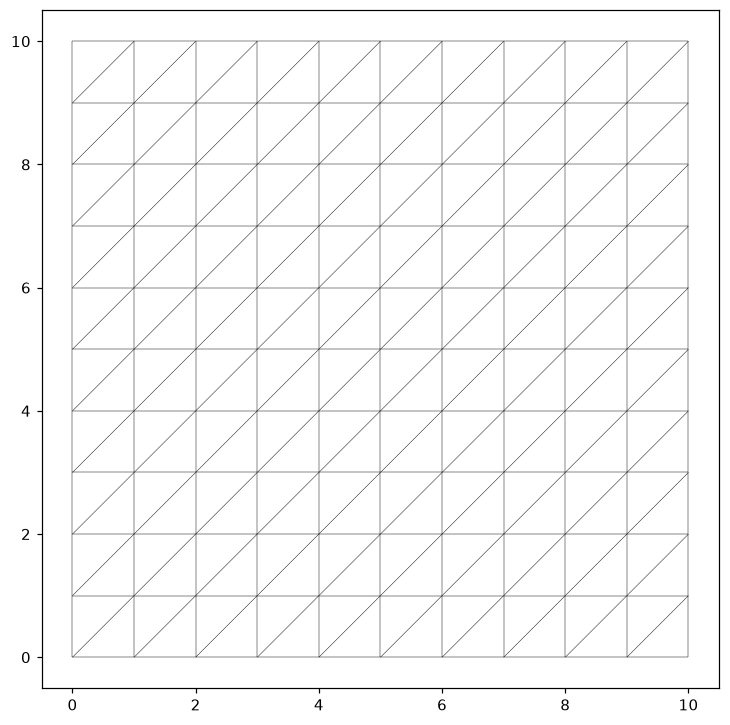

In [6]:
ds.plot_outline()
show()

### Coloured map: cell area

We compute per-cell area from the geometry (`mesh.face_areas`), attach it as a face variable with `with_variable(..., location="face")`, and colour each cell by it. A constant-area triangulation shows up as a single flat colour.

cell area  min: 0.5  max: 0.5  mean: 0.5


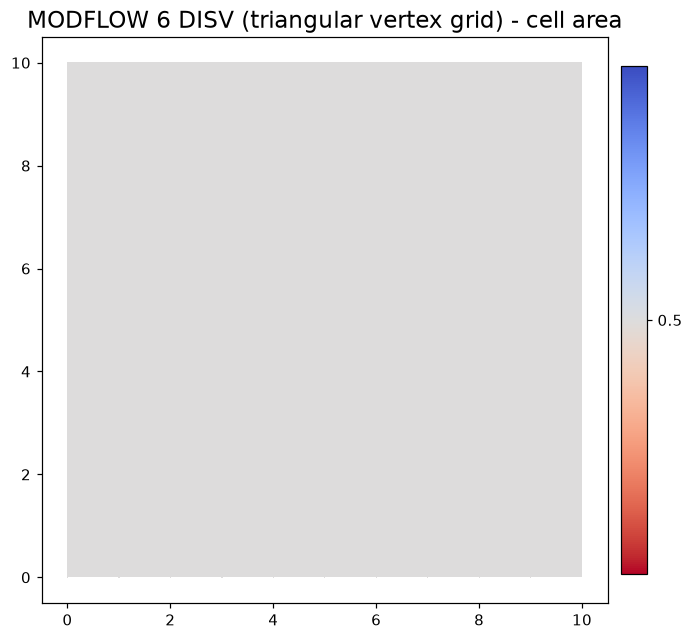

In [7]:
areas = np.asarray(ds.mesh.face_areas)
print("cell area  min: %.4g  max: %.4g  mean: %.4g" % (areas.min(), areas.max(), areas.mean()))
d2 = ds.with_variable("cell_area", areas, location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="MODFLOW 6 DISV (triangular vertex grid) - cell area")
show()

### Deeper: centroids and bounds

`face_centroids` is a `(2, n_face)` array of cell-centre x/y - exactly what MODFLOW uses to place cell-centred heads. `bounds` gives the model extent.

In [8]:
cen = np.asarray(ds.mesh.face_centroids)
print("face_centroids shape:", cen.shape, "-> (x, y) per cell")
print("first 3 centroids (x):", np.round(cen[0, :3], 3))
print("first 3 centroids (y):", np.round(cen[1, :3], 3))
print("mesh.bounds (minx, miny, maxx, maxy):", tuple(np.round(ds.mesh.bounds, 3)))

face_centroids shape: (2, 200) -> (x, y) per cell
first 3 centroids (x): [0.33 0.67 1.33]
first 3 centroids (y): [9.67 9.33 9.67]
mesh.bounds (minx, miny, maxx, maxy): (np.float64(0.0), np.float64(0.0), np.float64(10.0), np.float64(10.0))


### As a GeoDataFrame

`to_geodataframe()` hands the footprint to the vector world as one polygon per cell. There is **no CRS** (`crs = None`): DISV coordinates are model-local units, not a geographic projection.

In [9]:
gdf = ds.to_geodataframe()
print("rows:", len(gdf), "| columns:", list(gdf.columns), "| crs:", gdf.crs)
gdf.head()

rows: 200 | columns: ['geometry'] | crs: None


,geometry
0,"POLYGON ((0 9, 1 10, 0 10, 0 9))"
1,"POLYGON ((0 9, 1 9, 1 10, 0 9))"
2,"POLYGON ((1 9, 2 10, 1 10, 1 9))"
3,"POLYGON ((1 9, 2 9, 2 10, 1 9))"
4,"POLYGON ((2 9, 3 10, 2 10, 2 9))"


### Footprint via geopandas

Plotting the polygon boundaries reproduces the triangular grid as GIS geometry.

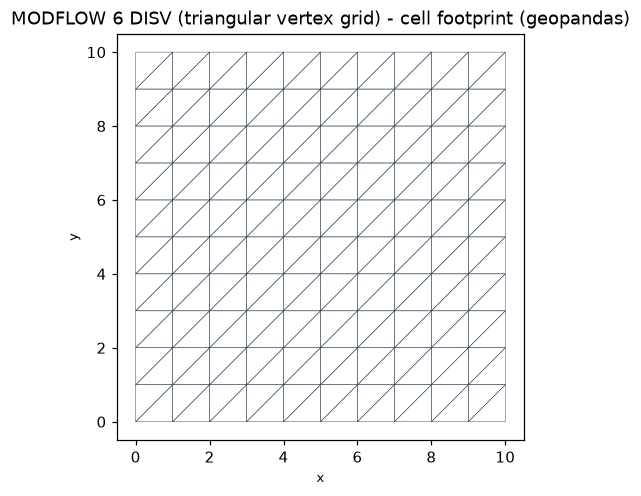

In [10]:
ax = gdf.boundary.plot(linewidth=0.3, color="#334155")
ax.set_aspect("equal")
ax.set_title("MODFLOW 6 DISV (triangular vertex grid) - cell footprint (geopandas)")
show()

### Interpretation

A clean, uniform triangulation: 200 equal-area triangles over a 10x10 domain, no CRS. DISV's value is exactly this - an irregular (here regular) horizontal footprint that stays vertically layered, so flow between layers is still a simple stack while the plan view is unstructured.

## 2. MODFLOW 6 DISU (fully unstructured grid)

`keating.disu` is the MODFLOW 6 `test016_Keating_disu_250` benchmark: **324 cells, 162 vertices, 2076 connections (NJA)**. DISU is the most general MODFLOW 6 grid - it abandons layers and rows/columns and instead lists, for every cell, its vertices and its neighbours. This sample is a thin vertical cross-section (a 2-D slice), tessellated into quadrilaterals.

### Read

`driver="modflow6_disu"` selects the unstructured reader. Node and face counts come straight from the file's `NODES`/`NVERT` records.

In [11]:
ds = UgridDataset.read_file(str(DATA / "modflow6_disu" / "keating.disu"), driver="modflow6_disu")
print(type(ds).__name__, "from", "keating.disu")
print("nodes:", ds.n_node, "| faces (cells):", ds.n_face, "| edges:", ds.n_edge)
print("crs:", ds.crs)

UgridDataset from keating.disu
nodes: 162 | faces (cells): 324 | edges: 0
crs: None


C:\python-environments\worktrees\pyramids-mesh\example-notebooks\src\pyramids_mesh\_base.py:484: UserWarning: 324 clockwise face(s) were reversed to counter-clockwise; a writer will emit the corrected order
  parsed = validate_and_normalise(parsed)


### Structure and summary

Again geometry-only, so `summary()` is empty. The degree distribution shows every cell is a quadrilateral (degree 4). DISU *can* mix cell shapes - the `-1` fill in the face table exists precisely to allow ragged rows - but this particular grid is uniform quads.

In [12]:
print("UgridDataset.summary() (describes data variables):")
display(ds.summary())
print("data variables:", ds.data_variable_names or "<none - geometry only>")
print("nodes:", ds.n_node, "| faces:", ds.n_face)
print("face-degree distribution {degree: count}:", degree_distribution(ds))

UgridDataset.summary() (describes data variables):


,count,min,max,mean,std
variable,,,,,


data variables: <none - geometry only>
nodes: 162 | faces: 324
face-degree distribution {degree: count}: {4: 324}


### Mesh outline

The outline reveals the long, thin cross-section: DISU coordinates here are a vertical slice, so x spans the domain and y is a narrow depth band.

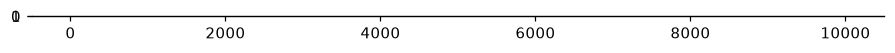

In [13]:
ds.plot_outline()
show()

### Coloured map: cell area

Colouring by `face_areas` exposes the one place the grid is **not** uniform: the edge columns are half-width refinement cells, so their area differs from the interior cells.

cell area  min: 125  max: 250  mean: 246.9


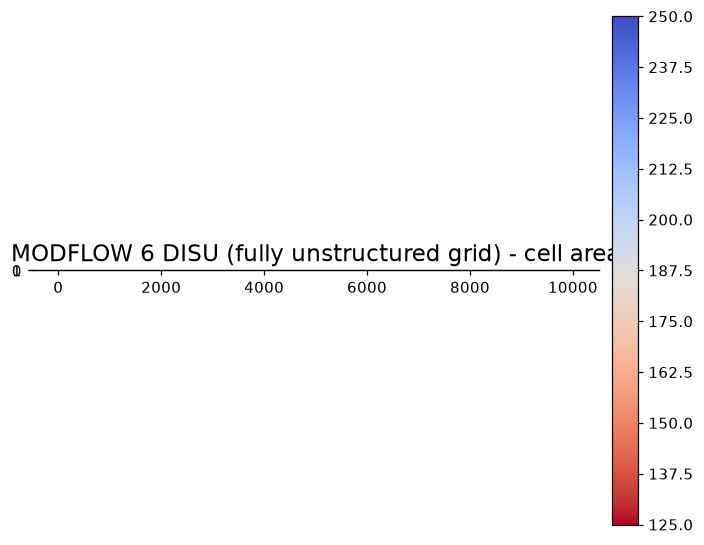

In [14]:
areas = np.asarray(ds.mesh.face_areas)
print("cell area  min: %.4g  max: %.4g  mean: %.4g" % (areas.min(), areas.max(), areas.mean()))
d2 = ds.with_variable("cell_area", areas, location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="MODFLOW 6 DISU (fully unstructured grid) - cell area")
show()

### Deeper: centroids and bounds

The centroids trace the slice; `bounds` shows the extreme aspect ratio (wide x, shallow y) typical of a 1-D-into-the-page cross-section.

In [15]:
cen = np.asarray(ds.mesh.face_centroids)
print("face_centroids shape:", cen.shape, "-> (x, y) per cell")
print("first 3 centroids (x):", np.round(cen[0, :3], 3))
print("first 3 centroids (y):", np.round(cen[1, :3], 3))
print("mesh.bounds (minx, miny, maxx, maxy):", tuple(np.round(ds.mesh.bounds, 3)))

face_centroids shape: (2, 324) -> (x, y) per cell
first 3 centroids (x): [125. 375. 625.]
first 3 centroids (y): [0.5 0.5 0.5]
mesh.bounds (minx, miny, maxx, maxy): (np.float64(0.0), np.float64(0.0), np.float64(10000.0), np.float64(1.0))


### As a GeoDataFrame

Each quad becomes a polygon. CRS is again `None` - a DISU slice lives in model coordinates, not on the globe.

In [16]:
gdf = ds.to_geodataframe()
print("rows:", len(gdf), "| columns:", list(gdf.columns), "| crs:", gdf.crs)
gdf.head()

rows: 324 | columns: ['geometry'] | crs: None


,geometry
0,"POLYGON ((250 0, 250 1, 0 1, 0 0, 250 0))"
1,"POLYGON ((500 0, 500 1, 250 1, 250 0, 500 0))"
2,"POLYGON ((750 0, 750 1, 500 1, 500 0, 750 0))"
3,"POLYGON ((1000 0, 1000 1, 750 1, 750 0, 1000 0))"
4,"POLYGON ((1250 0, 1250 1, 1000 1, 1000 0, 1250..."


### Footprint via geopandas

The boundary plot makes the refined end-columns visible against the coarser interior.

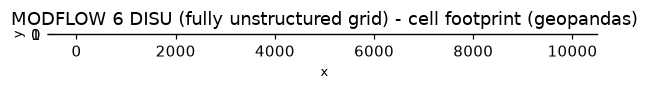

In [17]:
ax = gdf.boundary.plot(linewidth=0.3, color="#334155")
ax.set_aspect("equal")
ax.set_title("MODFLOW 6 DISU (fully unstructured grid) - cell footprint (geopandas)")
show()

### Interpretation

A fully unstructured grid that happens to be regular quads, with half-size refinement cells at the two ends - visible both in the area map and the footprint. DISU is the format to reach for when the discretisation follows geology rather than a regular raster.

## 3. FEFLOW (finite-element mesh)

`disv_nodes.fem` is a DHI **FEFLOW** classic ASCII mesh (CLASS v7.501) from the MODFLOW 6 `ex-gwe-ates` example: **2496 nodes, 4842 triangular elements**. FEFLOW is finite-element rather than finite-difference/volume, so its native object is a triangular (or quad) element mesh. The driver reads those elements into the same `UgridDataset` faces.

### Read

`driver="feflow"` parses the `.fem` DIMENS/NODE/ELEMENTS blocks. 4842 faces is much larger than the MODFLOW samples - a real FE discretisation.

In [18]:
ds = UgridDataset.read_file(str(DATA / "feflow" / "disv_nodes.fem"), driver="feflow")
print(type(ds).__name__, "from", "disv_nodes.fem")
print("nodes:", ds.n_node, "| faces (cells):", ds.n_face, "| edges:", ds.n_edge)
print("crs:", ds.crs)

UgridDataset from disv_nodes.fem
nodes: 2496 | faces (cells): 4842 | edges: 0
crs: None


### Structure and summary

Geometry-only once more (empty `summary()`); the degree distribution confirms a pure triangular FE mesh (every element degree 3).

In [19]:
print("UgridDataset.summary() (describes data variables):")
display(ds.summary())
print("data variables:", ds.data_variable_names or "<none - geometry only>")
print("nodes:", ds.n_node, "| faces:", ds.n_face)
print("face-degree distribution {degree: count}:", degree_distribution(ds))

UgridDataset.summary() (describes data variables):


,count,min,max,mean,std
variable,,,,,


data variables: <none - geometry only>
nodes: 2496 | faces: 4842
face-degree distribution {degree: count}: {3: 4842}


### Mesh outline

With ~4800 triangles the outline is dense - you can see the mesh refine towards features. This is an ATES (aquifer thermal energy storage) layout.

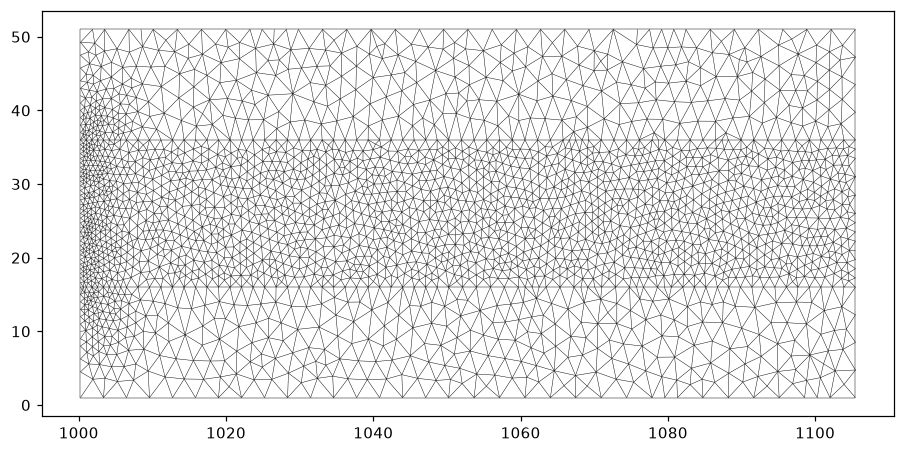

In [20]:
ds.plot_outline()
show()

### Coloured map: cell area

Unlike the MODFLOW samples, FE element areas vary widely (mesh refinement), so the viridis map has real contrast: small cells where accuracy matters, large cells in the far field.

cell area  min: 0.07691  max: 5.66  mean: 1.087


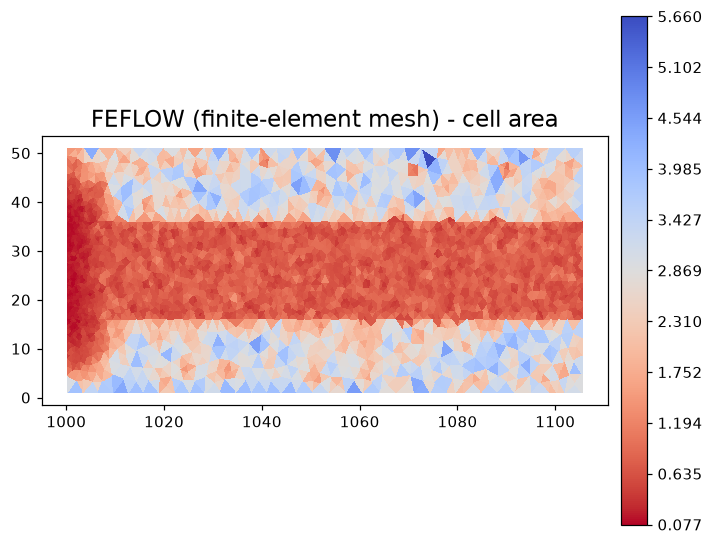

In [21]:
areas = np.asarray(ds.mesh.face_areas)
print("cell area  min: %.4g  max: %.4g  mean: %.4g" % (areas.min(), areas.max(), areas.mean()))
d2 = ds.with_variable("cell_area", areas, location="face")
d2.plot("cell_area", cmap="viridis", colorbar=True, title="FEFLOW (finite-element mesh) - cell area")
show()

### Deeper: centroids and bounds

`face_centroids` now holds 4842 element centres; `bounds` shows this is a small local patch (roughly 105 x 50 model units) - again with no CRS attached.

In [22]:
cen = np.asarray(ds.mesh.face_centroids)
print("face_centroids shape:", cen.shape, "-> (x, y) per cell")
print("first 3 centroids (x):", np.round(cen[0, :3], 3))
print("first 3 centroids (y):", np.round(cen[1, :3], 3))
print("mesh.bounds (minx, miny, maxx, maxy):", tuple(np.round(ds.mesh.bounds, 3)))

face_centroids shape: (2, 4842) -> (x, y) per cell
first 3 centroids (x): [1097.921 1103.107 1055.736]
first 3 centroids (y): [19.177 20.175 14.113]
mesh.bounds (minx, miny, maxx, maxy): (np.float64(1000.234), np.float64(1.0), np.float64(1105.469), np.float64(51.0))


### As a GeoDataFrame

4842 triangular polygons. CRS `None`: FEFLOW stores engineering coordinates, so attach a CRS downstream only if you know the project's datum.

In [23]:
gdf = ds.to_geodataframe()
print("rows:", len(gdf), "| columns:", list(gdf.columns), "| crs:", gdf.crs)
gdf.head()

rows: 4842 | columns: ['geometry'] | crs: None


,geometry
0,"POLYGON ((1098.585 18.98, 1097.598 20.103, 109..."
1,"POLYGON ((1102.732 20.736, 1102.94 19.368, 110..."
2,"POLYGON ((1054.496 12.832, 1056.808 13.507, 10..."
3,"POLYGON ((1043.423 39.218, 1042.422 36, 1043.9..."
4,"POLYGON ((1026.183 17.39, 1025.96 18.835, 1025..."


### Footprint via geopandas

The geopandas boundary plot shows the graded triangulation - fine near the wells, coarse at the boundary.

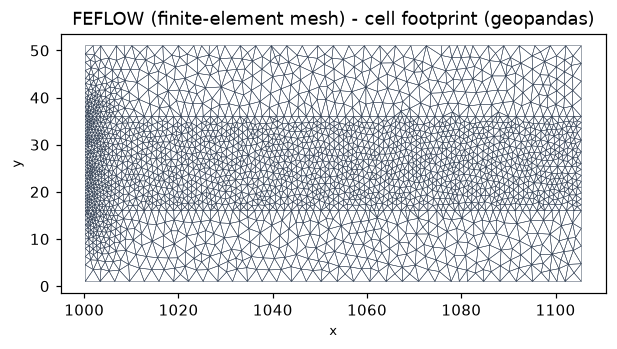

In [24]:
ax = gdf.boundary.plot(linewidth=0.3, color="#334155")
ax.set_aspect("equal")
ax.set_title("FEFLOW (finite-element mesh) - cell footprint (geopandas)")
show()

### Interpretation

A genuine finite-element mesh: thousands of triangles with strongly varying element size, the hallmark of FE refinement. The area map and footprint both reveal where the modeller invested resolution. pyramids reads it into the same mesh model as the MODFLOW grids, so downstream GIS and plotting code treats all three identically.

## Summary

Three subsurface mesh formats, one API:

- **MODFLOW 6 DISV** (`modflow6_disv`) - a vertex grid; here 200 equal triangles over a 10x10 layer.
- **MODFLOW 6 DISU** (`modflow6_disu`) - a fully unstructured grid; here a 324-quad vertical slice with
  refined end-columns.
- **FEFLOW** (`feflow`) - a finite-element mesh; here 4842 graded triangles.

Each `read_file(..., driver=...)` call returns a pyramids `UgridDataset`, after which **everything is
pyramids**: `n_node`/`n_face`, `face_node_connectivity`, `face_areas`, `face_centroids`, `bounds`,
`to_geodataframe()` and cleopatra-backed plotting. All three samples come in with `crs = None` because
groundwater models use local engineering coordinates - set a CRS downstream only when you know the
project datum. `pyramids-mesh` contributes only the parsing; the mesh science lives upstream.